# Network Intrusion Detection System Using Supervised Machine Learning

This notebook demonstrates the end-to-end machine learning pipeline for detecting network attacks using the CICIDS2017 dataset.

### Steps in this notebook:
1. Load Dataset and Memory Optimization
2. Data Cleaning and Preprocessing (12 Classes)
3. Exploratory Data Analysis (EDA)
4. Train-Test Split and Feature Scaling
5. Model 1: Decision Tree Classifier
6. Model 2: Random Forest Classifier
7. Evaluation (Accuracy, Confusion Matrix, Classification Report)
8. Save Model Pipeline

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import glob
import os
import zipfile
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


## 1. Extract Dataset and Memory Optimization

In [2]:
# Extract the dataset zip file
zip_path = "MachineLearningCSV.zip"
if not os.path.exists(zip_path):
    zip_path = "/content/MachineLearningCSV.zip"

if os.path.exists(zip_path):
    print("Extracting dataset zip file...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/")
    print("Dataset extracted successfully.")
else:
    print("Note: MachineLearningCSV.zip not found in current folder.")


Extracting dataset zip file...
Dataset extracted successfully.


In [3]:
# Function to reduce memory usage by downcasting datatypes
def reduce_memory(data):
    for col in data.columns:
        col_type = data[col].dtype
        if col_type == "float64":
            data[col] = data[col].astype("float32")
        elif col_type == "int64":
            data[col] = data[col].astype("int32")
    return data


In [4]:
# Automatically find all 8 unique attack CSV files
unique_files = {}
all_csvs = glob.glob("/content/**/*.csv", recursive=True) + glob.glob("**/*.csv", recursive=True)
for f in all_csvs:
    fname = os.path.basename(f)
    if "sample_data" not in f and not fname.startswith("sample_test_flows"):
        unique_files[fname] = f

csv_files = sorted(list(unique_files.values()))
print(f"Found {len(csv_files)} attack CSV files to load.")

# Load all CSV files and combine them
df_list = []
for file in csv_files:
    print("Loading:", os.path.basename(file))
    temp_df = pd.read_csv(file)
    temp_df.columns = temp_df.columns.str.strip()
    temp_df = reduce_memory(temp_df)
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)
print("Total dataset shape:", df.shape)


Found 8 attack CSV files to load.
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Total dataset shape: (2830743, 79)


In [5]:
# Display first 5 rows
df.head()


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## 2. Data Cleaning and Preprocessing

In [6]:
# Replace infinite values with NaN and drop missing values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
print("Shape after dropping NaN and Inf:", df.shape)


Shape after dropping NaN and Inf: (2827876, 79)


In [7]:
# Drop duplicate rows
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)


Shape after dropping duplicates: (2498185, 79)


In [8]:
# Filter out negative flow duration values
df = df[df["Flow Duration"] >= 0]
print("Shape after filtering negative durations:", df.shape)


Shape after filtering negative durations: (2498078, 79)


In [9]:
# Drop constant columns having zero variance
constant_columns = [col for col in df.columns if df[col].nunique() <= 1]
print("Dropping constant columns:", constant_columns)
df = df.drop(columns=constant_columns)
print("Remaining columns count:", len(df.columns))


Dropping constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Remaining columns count: 71


In [10]:
# Consolidate rare attack variants into 12 main classes
df.loc[df["Label"].str.contains("Web Attack", case=False, na=False), "Label"] = "Web Attack"
df.loc[df["Label"].str.contains("Heartbleed", case=False, na=False), "Label"] = "Infiltration"

print("Total unique classes:", df["Label"].nunique())
print("Consolidated class distribution:")
print(df["Label"].value_counts())


Total unique classes: 12
Consolidated class distribution:
Label
BENIGN              2072337
DoS Hulk             172846
DDoS                 128014
PortScan              90694
DoS GoldenEye         10286
FTP-Patator            5931
DoS slowloris          5385
DoS Slowhttptest       5228
SSH-Patator            3219
Web Attack             2143
Bot                    1948
Infiltration             47
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)

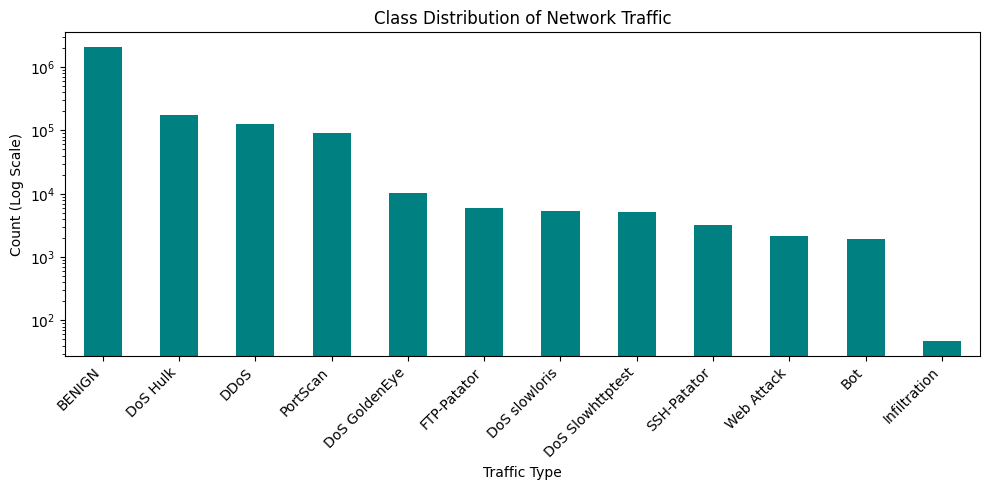

In [11]:
# Plot class distribution of network traffic on a logarithmic scale
plt.figure(figsize=(10, 5))
df["Label"].value_counts().plot(kind="bar", color="teal")
plt.title("Class Distribution of Network Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Count (Log Scale)")
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


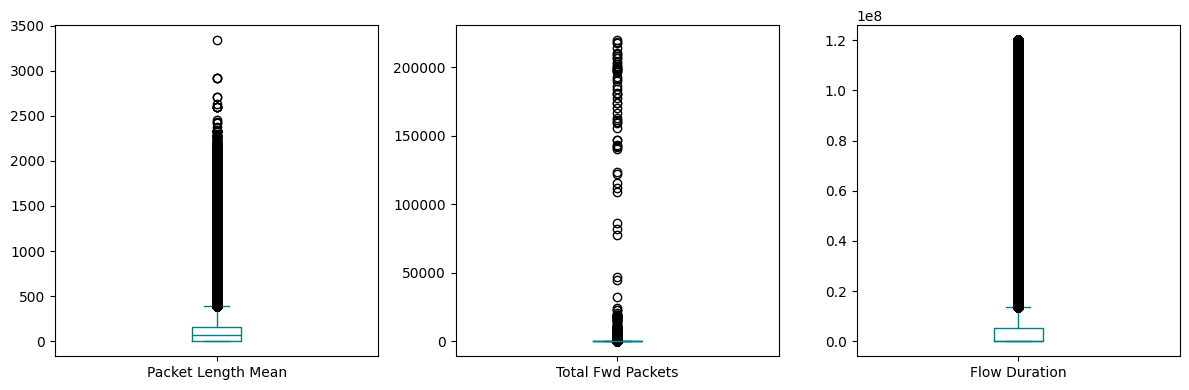

In [12]:
# Plot boxplots for key numerical features to inspect distributions
features_to_plot = ["Packet Length Mean", "Total Fwd Packets", "Flow Duration"]
df[features_to_plot].plot(kind="box", subplots=True, layout=(1, 3), figsize=(12, 4), color="teal")
plt.tight_layout()
plt.show()


## 4. Train-Test Split and Feature Scaling

In [13]:
# Encode target labels to integers
label_encoder = LabelEncoder()
df["Label_Encoded"] = label_encoder.fit_transform(df["Label"])

# Display label mapping
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
for label, code in label_mapping.items():
    print(f"{code} -> {label}")


0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Infiltration
9 -> PortScan
10 -> SSH-Patator
11 -> Web Attack


In [14]:
# Separate features and target
X = df.drop(columns=["Label", "Label_Encoded"])
y = df["Label_Encoded"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (2498078, 70)
Target shape: (2498078,)


In [15]:
# Split the dataset into 80% training and 20% testing data with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1998462
Testing samples: 499616


In [16]:
# Apply StandardScaler for feature scaling
scaler = StandardScaler()

# Fit on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")


Feature scaling completed successfully.


## 5. Model 1: Decision Tree Classifier

In [17]:
# Create the Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    max_depth=15,
    class_weight="balanced",
    random_state=42
)

# Train Decision Tree model
dt_model.fit(X_train_scaled, y_train)

# Predict target values on test data
y_pred_dt = dt_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", round(accuracy_dt * 100, 2), "%")


Decision Tree Accuracy: 98.17 %


## 6. Model 2: Random Forest Classifier (Selected Model)

In [23]:
# Create the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train Random Forest model
rf_model.fit(X_train_scaled, y_train)



RandomForestClassifier(class_weight='balanced', max_depth=15, n_estimators=50,
                       n_jobs=-1, random_state=42)

In [24]:
# Predict target values on test data
y_pred_rf = rf_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")


Random Forest Accuracy: 99.28 %


In [25]:
# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))


Classification Report:
                  precision    recall  f1-score   support

          BENIGN       1.00      0.99      1.00    414468
             Bot       0.12      0.99      0.21       389
            DDoS       1.00      1.00      1.00     25603
   DoS GoldenEye       0.98      1.00      0.99      2057
        DoS Hulk       0.99      1.00      0.99     34569
DoS Slowhttptest       0.99      0.99      0.99      1046
   DoS slowloris       0.99      0.99      0.99      1077
     FTP-Patator       1.00      1.00      1.00      1186
    Infiltration       1.00      0.67      0.80         9
        PortScan       0.99      1.00      0.99     18139
     SSH-Patator       0.97      1.00      0.98       644
      Web Attack       0.89      0.99      0.94       429

        accuracy                           0.99    499616
       macro avg       0.91      0.97      0.91    499616
    weighted avg       1.00      0.99      1.00    499616



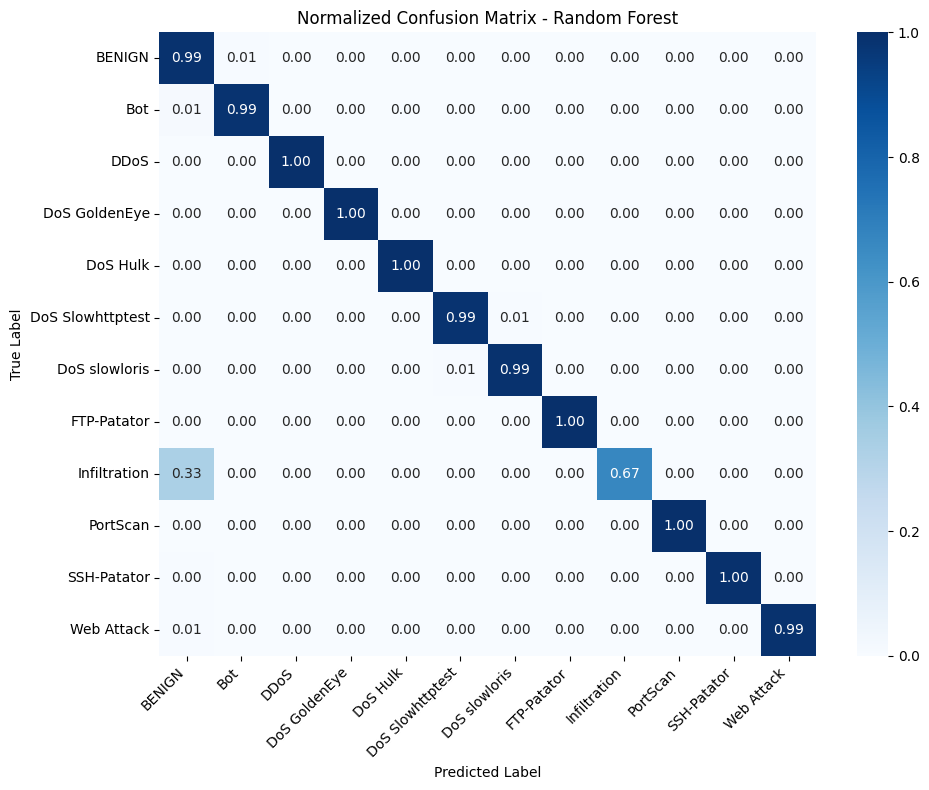

In [26]:
# Display normalized confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred_rf, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Normalized Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


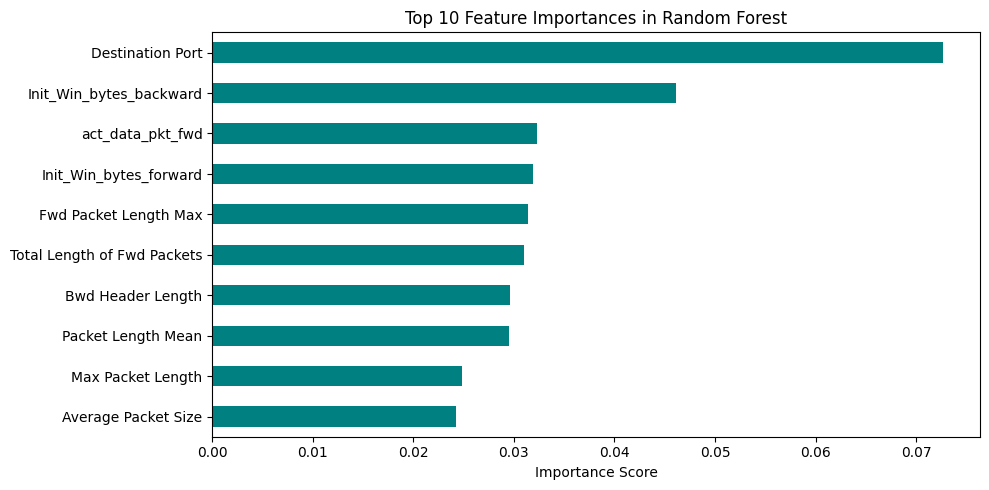

In [27]:
# Plot top 10 important features
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top10_features = importances.nlargest(10)

plt.figure(figsize=(10, 5))
top10_features.sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Feature Importances in Random Forest")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()


## 7. Save Model Pipeline